# EDA исходных датасетов

Анализируем [финансовые жалобы](https://huggingface.co/datasets/BEE-spoke-data/consumer-finance-complaints) и [винные этикетки](https://huggingface.co/datasets/LibreYOLO/wine-labels) из закреплённых версий источников.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display

ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'docs/text/codebook.md').exists()), None)
assert ROOT is not None, 'Запускайте ноутбук из клонированного репозитория или его папки notebooks/'
COLORS = ['#355C7D', '#D68135', '#519872', '#A65C7A']

plt.rcParams.update({'figure.dpi': 115, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold'})
print('Папка проекта найдена; кодбук текста: docs/text/codebook.md')

Папка проекта найдена; кодбук текста: docs/text/codebook.md


## Финансовые жалобы

Загружаем исходные тексты и проверяем четыре точные категории `Product` из [кодбука](../docs/text/codebook.md).

In [2]:
import pyarrow.parquet as pq

TEXT = 'Consumer complaint narrative'
PRODUCTS = ['Debt collection', 'Mortgage', 'Checking or savings account', 'Credit card']
PRODUCT_CODE = {name: index for index, name in enumerate(PRODUCTS)}
RU_TEXT = ['Взыскание долга', 'Ипотека', 'Банковский счёт', 'Кредитная карта']
NEEDED = ['Complaint ID', 'Date received', 'Product', TEXT]
FINANCE_REVISION = '088cc7308d4afc2a880f2329d08e2f7a09188ec6'
FINANCE = Path(os.environ.get('FINANCE_SOURCE_DIR',
                              ROOT / 'work/eda/hf_finance/has-text')).expanduser()
FINANCE_FILES = sorted(FINANCE.glob('*.parquet'))

assert len(FINANCE_FILES) == 3, f'Нужны три Parquet-файла конфигурации has-text: {FINANCE}'
schema = pq.ParquetFile(FINANCE_FILES[0]).schema_arrow
assert set(NEEDED).issubset(schema.names), f'Не хватает колонок: {set(NEEDED) - set(schema.names)}'
print('Версия CFPB:', FINANCE_REVISION[:12])
print('Конфигурация: has-text; split: train; файлов:', len(FINANCE_FILES))
print('Колонок:', len(schema), '| Product:', schema.field('Product').type,
      '| narrative:', schema.field(TEXT).type)

Версия CFPB: 088cc7308d4a
Конфигурация: has-text; split: train; файлов: 3
Колонок: 18 | Product: string | narrative: string


Считаем объём выбранных классов, длину жалоб, пропуски и точные повторы без изменения текстов.

In [3]:
def finance_eda(files):
    product_counts = Counter()
    missing = Counter()
    codes, char_counts, word_counts, years = [], [], [], []
    seen_ids, seen_texts = set(), {}
    duplicate_ids = rows = 0
    date_min = date_max = None

    for file in files:
        for batch in pq.ParquetFile(file).iter_batches(batch_size=32768, columns=NEEDED):
            data = batch.to_pydict()
            rows += batch.num_rows
            product_counts.update(data['Product'])
            selected = [i for i, name in enumerate(data['Product']) if name in PRODUCT_CODE]
            if not selected:
                continue

            dates = pd.to_datetime([data['Date received'][i] for i in selected],
                                   errors='coerce', format='mixed')
            valid_dates = dates[~dates.isna()]
            if len(valid_dates):
                lo, hi = valid_dates.min(), valid_dates.max()
                date_min = min(date_min, lo) if date_min is not None else lo
                date_max = max(date_max, hi) if date_max is not None else hi

            for i, date in zip(selected, dates):
                name = data['Product'][i]
                complaint_id = data['Complaint ID'][i]
                narrative = data[TEXT][i]
                codes.append(PRODUCT_CODE[name])
                years.append(date.year if not pd.isna(date) else -1)

                if complaint_id is None:
                    missing['Нет Complaint ID'] += 1
                elif complaint_id in seen_ids:
                    duplicate_ids += 1
                else:
                    seen_ids.add(complaint_id)
                if pd.isna(date):
                    missing['Неверная или пустая дата'] += 1

                if narrative is None:
                    missing['Null narrative'] += 1
                    narrative = ''
                elif narrative == '':
                    missing['Пустой narrative'] += 1
                elif not narrative.strip():
                    missing['Только пробелы'] += 1

                char_counts.append(len(narrative))
                word_count = len(narrative.split())
                word_counts.append(word_count)
                if 0 < word_count <= 5:
                    missing['1–5 слов: проверить вручную'] += 1

                if narrative.strip():
                    digest = hashlib.sha256(narrative.encode('utf-8')).digest()
                    if digest in seen_texts:
                        seen_texts[digest][0] += 1
                        seen_texts[digest][1] |= 1 << PRODUCT_CODE[name]
                    else:
                        seen_texts[digest] = [1, 1 << PRODUCT_CODE[name]]

    selected_data = pd.DataFrame({'class_code': np.asarray(codes, dtype=np.int8),
                                  'characters': np.asarray(char_counts, dtype=np.int32),
                                  'words': np.asarray(word_counts, dtype=np.int32),
                                  'year': np.asarray(years, dtype=np.int16)})
    stats = {'rows': rows, 'products': product_counts, 'missing': missing,
             'duplicate_ids': duplicate_ids,
             'duplicate_text_groups': sum(count > 1 for count, _ in seen_texts.values()),
             'duplicate_text_rows': sum(count - 1 for count, _ in seen_texts.values()),
             'conflicting_text_groups': sum(mask.bit_count() > 1
                                            for _, mask in seen_texts.values()),
             'date_min': date_min, 'date_max': date_max}
    return stats, selected_data


fin, selected_data = finance_eda(FINANCE_FILES)
assert fin['rows'] == 1_689_573, f'Проверьте версию или полноту has-text: {fin["rows"]}'
assert not selected_data.empty
counts = pd.Series({name: fin['products'][name] for name in PRODUCTS})
selected_total = int(counts.sum())
print(f'Весь has-text: {fin["rows"]:,} записей; выбранная четвёрка: '
      f'{selected_total:,} ({selected_total / fin["rows"]:.1%})')
print('Даты выбранных классов:', fin['date_min'].date(), '—', fin['date_max'].date())
display(pd.DataFrame({'Исходная метка': PRODUCTS, 'Записей': counts.values,
                      'Доля выбранной четвёрки, %': (counts.values / selected_total * 100).round(2)})
        .set_index('Исходная метка'))
print('Отдельная исходная категория Credit card or prepaid card:',
      fin['products']['Credit card or prepaid card'])

Весь has-text: 1,689,573 записей; выбранная четвёрка: 466,577 (27.6%)
Даты выбранных классов: 2015-03-19 — 2024-02-09


,Записей,"Доля выбранной четвёрки, %"
Исходная метка,,
Debt collection,234027,50.16
Mortgage,113466,24.32
Checking or savings account,87250,18.70
Credit card,31834,6.82


Отдельная исходная категория Credit card or prepaid card: 108669


Сравниваем все исходные категории с распределением выбранной четвёрки.

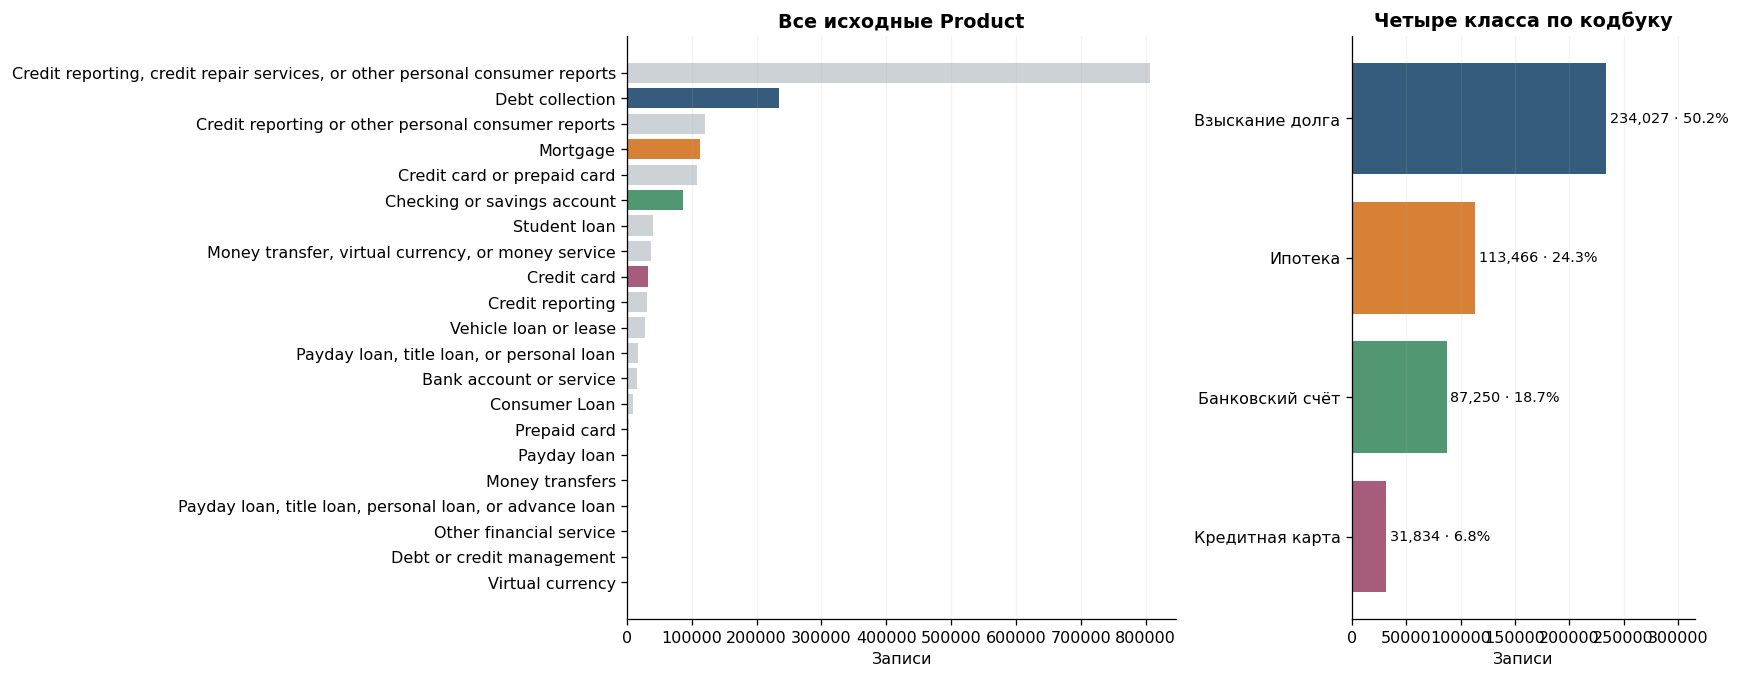

Отношение самого частого класса к самому редкому: 7.35


In [4]:
all_counts = pd.Series(fin['products']).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].barh([str(name) if name is not None else '<NULL>' for name in all_counts.index],
           all_counts.values,
           color=[COLORS[PRODUCT_CODE[name]] if name in PRODUCT_CODE else '#CDD2D7'
                  for name in all_counts.index])
ax[0].set(title='Все исходные Product', xlabel='Записи')
ax[0].grid(axis='x', alpha=.15)

ax[1].barh(RU_TEXT[::-1], counts.values[::-1], color=COLORS[::-1])
for i, value in enumerate(counts.values[::-1]):
    ax[1].text(value + counts.max() * .015, i,
               f'{value:,} · {value / selected_total:.1%}', va='center', fontsize=9)
ax[1].set(title='Четыре класса по кодбуку', xlabel='Записи',
          xlim=(0, counts.max() * 1.35))
ax[1].grid(axis='x', alpha=.15)
plt.tight_layout(); plt.show()
print('Отношение самого частого класса к самому редкому:',
      round(counts.max() / counts.min(), 2))

Показываем длины жалоб по классам и отмечаем короткие тексты для ручной проверки.

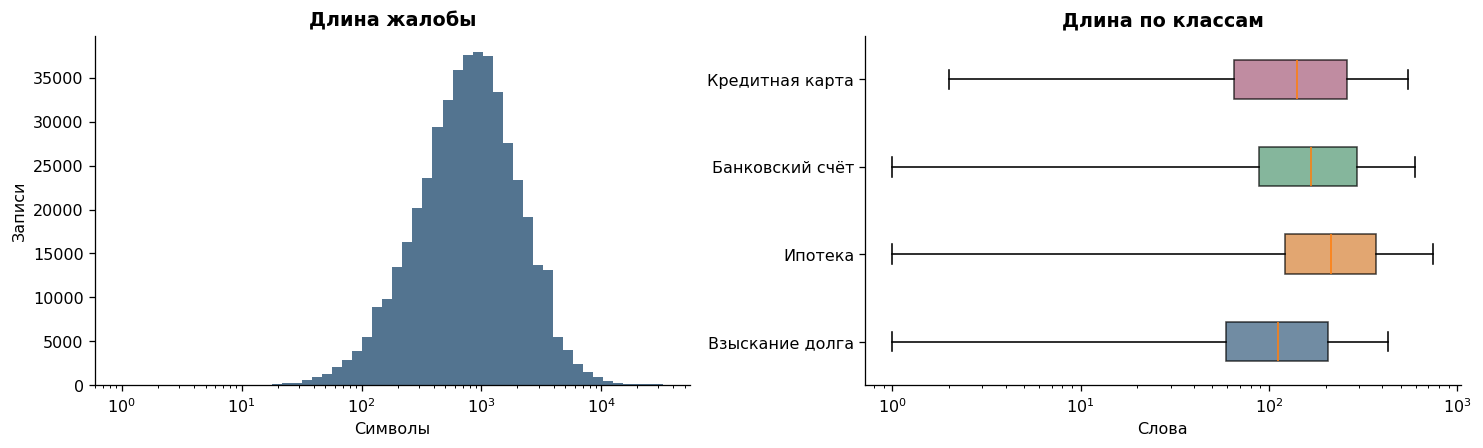

,Символы,Слова
min,11,1
p25,409,74
p50,793,145
p75,1465,267
p95,3546,639
p99,6362,1141
max,32763,6095


In [5]:
usable = selected_data[selected_data.words.gt(0)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(usable.characters, bins=np.geomspace(1, usable.characters.max() + 1, 55),
           color=COLORS[0], alpha=.85)
ax[0].set(xscale='log', title='Длина жалобы', xlabel='Символы', ylabel='Записи')

values = [usable.loc[usable.class_code.eq(i), 'words'] for i in range(4)]
box = ax[1].boxplot(values, showfliers=False, patch_artist=True, orientation='horizontal')
for patch, color in zip(box['boxes'], COLORS):
    patch.set_facecolor(color); patch.set_alpha(.7)
ax[1].set_yticks(range(1, 5), RU_TEXT)
ax[1].set(xscale='log', title='Длина по классам', xlabel='Слова')
plt.tight_layout(); plt.show()

quantiles = selected_data[['characters', 'words']].quantile([0, .25, .5, .75, .95, .99, 1])
quantiles.index = ['min', 'p25', 'p50', 'p75', 'p95', 'p99', 'max']
display(quantiles.rename(columns={'characters': 'Символы', 'words': 'Слова'}).round(0).astype(int))

Проверяем годы, повторные ID и одинаковые тексты с разными исходными метками.

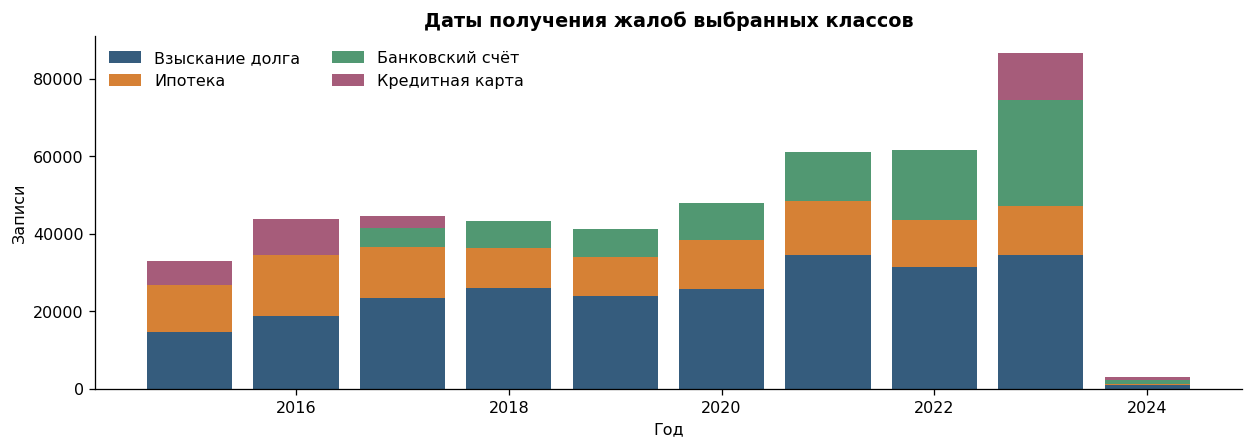

,Количество
Null narrative,0
Пустой narrative,0
Только пробелы,0
1–5 слов: проверить вручную,821
Нет Complaint ID,0
Повторных Complaint ID,0
Неверная или пустая дата,0
Групп одинаковых текстов,5016
Лишних копий одинакового текста,15621
Одинаковый текст с разными Product,51


У has-text только train. Перед созданием validation/test одинаковые тексты следует держать в одном split, чтобы не было утечки.


In [6]:
by_year = pd.crosstab(selected_data.loc[selected_data.year.ge(0), 'year'],
                      selected_data.loc[selected_data.year.ge(0), 'class_code'])
by_year = by_year.reindex(columns=range(4), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(by_year), dtype=int)
for i, name in enumerate(RU_TEXT):
    ax.bar(by_year.index, by_year[i], bottom=bottom, color=COLORS[i], label=name)
    bottom += by_year[i].to_numpy()
ax.set(title='Даты получения жалоб выбранных классов', xlabel='Год', ylabel='Записи')
ax.legend(ncol=2, frameon=False)
plt.tight_layout(); plt.show()

checks = pd.Series({
    'Null narrative': fin['missing']['Null narrative'],
    'Пустой narrative': fin['missing']['Пустой narrative'],
    'Только пробелы': fin['missing']['Только пробелы'],
    '1–5 слов: проверить вручную': fin['missing']['1–5 слов: проверить вручную'],
    'Нет Complaint ID': fin['missing']['Нет Complaint ID'],
    'Повторных Complaint ID': fin['duplicate_ids'],
    'Неверная или пустая дата': fin['missing']['Неверная или пустая дата'],
    'Групп одинаковых текстов': fin['duplicate_text_groups'],
    'Лишних копий одинакового текста': fin['duplicate_text_rows'],
    'Одинаковый текст с разными Product': fin['conflicting_text_groups'],
}, name='Количество')
display(checks.to_frame())
print('У has-text только train. Перед созданием validation/test одинаковые тексты '
      'следует держать в одном split, чтобы не было утечки.')

## Винные этикетки

Загружаем исходные изображения и проверяем их размеры и рамки.

In [7]:
import yaml

WINE_REVISION = 'a5ad4a5ef85cfc1d1784614d78c54c77726ffb75'
SOURCE = Path(os.environ.get('WINE_SOURCE_DIR',
                             ROOT / 'work/eda/hf_wine_labels')).expanduser()
print('Версия Wine Labels:', WINE_REVISION[:12])
assert (SOURCE / 'data.yaml').exists(), f'Укажите путь к Wine Labels: {SOURCE}'
CLASSES = yaml.safe_load((SOURCE / 'data.yaml').read_text())['names']
TARGET = {'Maker-Name': 'Maker-Name', 'Distinct Logo': 'Distinct Logo',
          'TypeWine Type': 'TypeWine Type',
          'Appellation AOC DOC AVARegion': 'Appellation AOC DOC AVARegion'}
RU = {'Maker-Name': 'Производитель', 'Distinct Logo': 'Логотип',
      'TypeWine Type': 'Тип / сорт', 'Appellation AOC DOC AVARegion': 'Регион'}

def inspect_image(path, dataset, split, entities=None):
    raw = path.read_bytes()
    with Image.open(path) as im:
        width, height = im.size
        im.load()
        pixel_hash = hashlib.sha256(f'{im.mode}:{im.size}'.encode() + im.tobytes()).hexdigest()
    return dict(dataset=dataset, split=split, path=str(path), file=path.name,
                width=width, height=height, bytes=len(raw),
                sha256=hashlib.sha256(raw).hexdigest(), pixel_hash=pixel_hash,
                entities=entities or [])

images, boxes, issues = [], [], []
for split in ['train', 'valid', 'test']:
    for path in sorted((SOURCE / split / 'images').glob('*')):
        if not path.is_file():
            continue
        try:
            images.append(inspect_image(path, 'Wine Labels', split))
        except Exception as e:
            issues.append((str(path), f'изображение: {e}'))
            continue
        label = SOURCE / split / 'labels' / (path.stem + '.txt')
        if not label.exists():
            issues.append((str(path), 'нет файла разметки'))
            continue
        for line_no, line in enumerate(label.read_text().splitlines(), 1):
            if not line.strip():
                continue
            try:
                values = np.array([float(x) for x in line.split()])
                assert len(values) == 5 and np.isfinite(values).all()
                cls, xc, yc, w, h = values
                assert cls == int(cls) and 0 <= cls < len(CLASSES)
                assert 0 <= xc <= 1 and 0 <= yc <= 1 and 0 < w <= 1 and 0 < h <= 1
                outside = (xc-w/2 < -1e-5 or yc-h/2 < -1e-5 or
                           xc+w/2 > 1+1e-5 or yc+h/2 > 1+1e-5)
                boxes.append(dict(path=str(path), split=split, cls=int(cls),
                                  name=CLASSES[int(cls)], xc=xc, yc=yc, w=w, h=h,
                                  area=w*h, outside=outside))
            except (ValueError, AssertionError):
                issues.append((str(label), f'некорректная строка {line_no}'))
img = pd.DataFrame(images)
bbox = pd.DataFrame(boxes)
base = img[img.dataset.eq('Wine Labels')].copy()
assert len(base) == 4643, f'Исходный набор загружен не полностью: {len(base)} / 4643'
assert not bbox.empty
summary = img.groupby('dataset').agg(Изображений=('path','size'),
            МБ=('bytes', lambda s: round(s.sum()/1e6, 1)),
            Медианная_ширина=('width','median'), Медианная_высота=('height','median'))
summary['Боксов'] = len(bbox)
display(summary)
print('Фактические размеры Wine Labels:', base.groupby(['width','height']).size().to_dict())
print('Ошибок чтения / формата:', len(issues),
      '| Боксов за границами изображения:', int(bbox.outside.sum()))

Версия Wine Labels: a5ad4a5ef85c


,Изображений,МБ,Медианная_ширина,Медианная_высота,Боксов
dataset,,,,,
Wine Labels,4643,171.9,640.0,640.0,25034


Фактические размеры Wine Labels: {(640, 640): 4643}
Ошибок чтения / формата: 0 | Боксов за границами изображения: 0


Сравниваем исходные разделы train, valid и test, а также число рамок каждого класса.

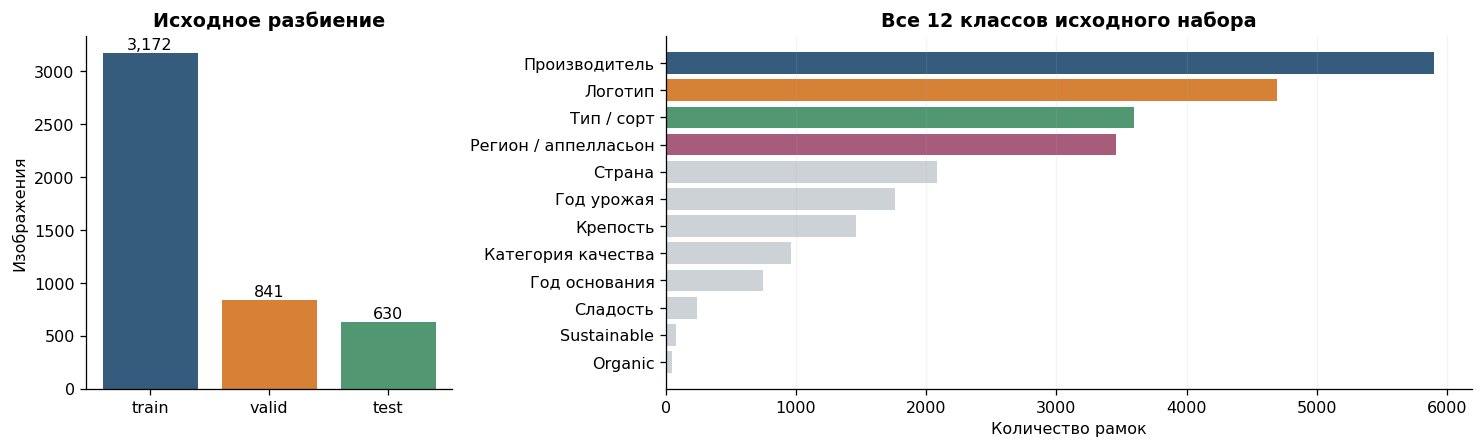

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios':[1, 2.2]})
splits = base.split.value_counts().reindex(['train','valid','test'])
ax[0].bar(splits.index, splits.values, color=COLORS[:3])
for x, value in enumerate(splits):
    ax[0].text(x, value+35, f'{value:,}', ha='center')
ax[0].set(title='Исходное разбиение', ylabel='Изображения')
counts = bbox.name.value_counts().reindex(CLASSES, fill_value=0).sort_values()
colors = [COLORS[list(TARGET.values()).index(x)] if x in TARGET.values() else '#CDD2D7' for x in counts.index]
short_names = {
    'Appellation AOC DOC AVARegion':'Регион / аппелласьон',
    'Appellation QualityLevel':'Категория качества', 'CountryCountry':'Страна',
    'Distinct Logo':'Логотип', 'Established YearYear':'Год основания',
    'Maker-Name':'Производитель', 'AlcoholPercentage':'Крепость',
    'Organic':'Organic', 'Sustainable':'Sustainable',
    'Sweetness-Brut-SecSweetness-Brut-Sec':'Сладость',
    'TypeWine Type':'Тип / сорт', 'VintageYear':'Год урожая'}
ax[1].barh([short_names[x] for x in counts.index], counts.values, color=colors)
ax[1].set(title='Все 12 классов исходного набора', xlabel='Количество рамок')
ax[1].grid(axis='x', alpha=.15)
plt.tight_layout(); plt.show()

Считаем присутствие и совместное появление четырёх выбранных полей на изображениях.

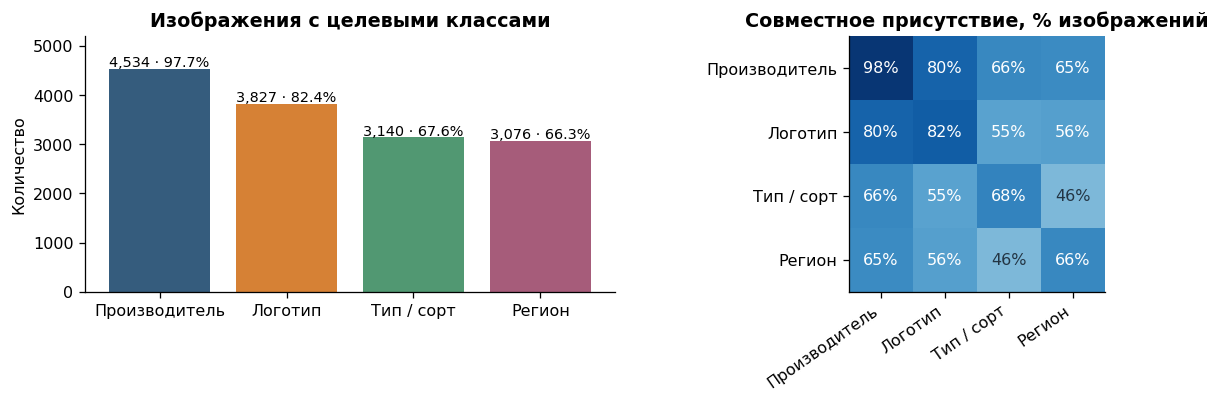

In [9]:
presence = pd.DataFrame(False, index=base.path, columns=TARGET)
for key, original_name in TARGET.items():
    presence.loc[bbox.loc[bbox.name.eq(original_name), 'path'].unique(), key] = True
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
n = presence.sum()
ax[0].bar(list(RU.values()), n, color=COLORS)
for i,v in enumerate(n):
    ax[0].text(i,v+40,f'{v:,} · {v/len(base):.1%}',ha='center',fontsize=9)
ax[0].set(title='Изображения с целевыми классами', ylabel='Количество', ylim=(0,len(base)*1.12))
a=presence.astype(int);co=a.T@a
ax[1].imshow(co.values/len(a)*100,cmap='Blues',vmin=0,vmax=100)
ax[1].set(xticks=range(4),yticks=range(4),xticklabels=list(RU.values()),
          yticklabels=list(RU.values()),title='Совместное присутствие, % изображений')
plt.setp(ax[1].get_xticklabels(),rotation=35,ha='right')
for i in range(4):
    for j in range(4):
        pct=co.iloc[i,j]/len(a)*100
        ax[1].text(j,i,f'{pct:.0f}%',ha='center',va='center',color='white' if pct>55 else '#233544')
plt.tight_layout();plt.show()

Проверяем размеры рамок четырёх выбранных полей.

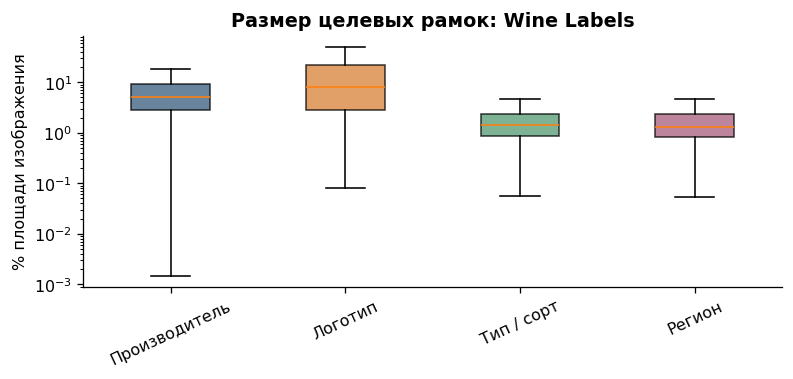

,"Медиана площади рамки, %","Медиана ширины рамки, px","Медиана высоты рамки, px","Рамок меньше 1% площади, %"
Поле,,,,
Производитель,5.20,336.5,63.5,5.7
Логотип,8.04,212.5,157.0,6.7
Тип / сорт,1.46,198.0,28.5,31.3
Регион,1.30,204.0,26.0,36.0


In [10]:
fig, axis = plt.subplots(figsize=(7,3.4))
areas = [bbox.loc[bbox.name.eq(name),'area']*100 for name in TARGET.values()]
bp = axis.boxplot(areas, showfliers=False, patch_artist=True)
axis.set_xticks(range(1,5), list(RU.values()))
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color); patch.set_alpha(.75)
axis.set(yscale='log', ylabel='% площади изображения', title='Размер целевых рамок: Wine Labels')
axis.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
pixel_boxes = bbox.merge(base[['path','width','height']], on='path', validate='many_to_one')
field_sizes = []
for key, original_name in TARGET.items():
    b = pixel_boxes[pixel_boxes.name.eq(original_name)]
    field_sizes.append({'Поле':RU[key], 'Медиана площади рамки, %':round(float(b.area.median()*100),2), 'Медиана ширины рамки, px':round((b.w*b.width).median(),1),
        'Медиана высоты рамки, px':round((b.h*b.height).median(),1),
        'Рамок меньше 1% площади, %':round(float((b.area<.01).mean()*100),1)})
display(pd.DataFrame(field_sizes).set_index('Поле'))

Ищем одинаковые изображения, повторы между разделами и файлы без рамок.

In [11]:
def duplicate_stats(frame, key):
    sizes = frame.groupby(key).size()
    return int((sizes>1).sum()), int((sizes-1).clip(lower=0).sum())
checks=[]
for label, frame in [('Wine Labels',base)]:
    groups, repeats = duplicate_stats(frame,'sha256')
    pgroups, prepeats = duplicate_stats(frame,'pixel_hash')
    checks.append({'Набор':label,'Групп одинаковых файлов':groups,
                   'Лишних копий файлов':repeats,'Лишних копий по пикселям':prepeats})
display(pd.DataFrame(checks).set_index('Набор'))
leaks = base.groupby('pixel_hash').split.nunique()
print('Групп одинаковых пикселей в разных исходных split:', int((leaks>1).sum()))
inventory = ROOT / 'work/eda/hf_tree_full.json'
if inventory.exists():
    expected = {v['path']:v['lfs']['oid'] for v in json.loads(inventory.read_text())
                if '/images/' in v['path'] and 'lfs' in v}
    verified = sum(row.sha256 == expected.get(str(Path(row.path).relative_to(SOURCE)))
                   for row in base.itertuples())
    print('JPEG совпадают с SHA-256 репозитория:', verified, '/', len(base))
print('Изображений без рамок в исходном наборе:', int((~base.path.isin(bbox.path)).sum()))
print('Все четыре целевых класса:',int(presence.all(axis=1).sum()),'/',len(base))
print('Хотя бы три целевых класса:',int((presence.sum(axis=1)>=3).sum()),'/',len(base))
print('Хотя бы один целевой класс:',int(presence.any(axis=1).sum()),'/',len(base))
if issues:
    display(pd.DataFrame(issues,columns=['Файл','Замечание']).head(10))

,Групп одинаковых файлов,Лишних копий файлов,Лишних копий по пикселям
Набор,,,
Wine Labels,0,0,0


Групп одинаковых пикселей в разных исходных split: 0
Изображений без рамок в исходном наборе: 1
Все четыре целевых класса: 1746 / 4643
Хотя бы три целевых класса: 3680 / 4643
Хотя бы один целевой класс: 4641 / 4643


Показываем три примера изображений с рамками выбранных классов.

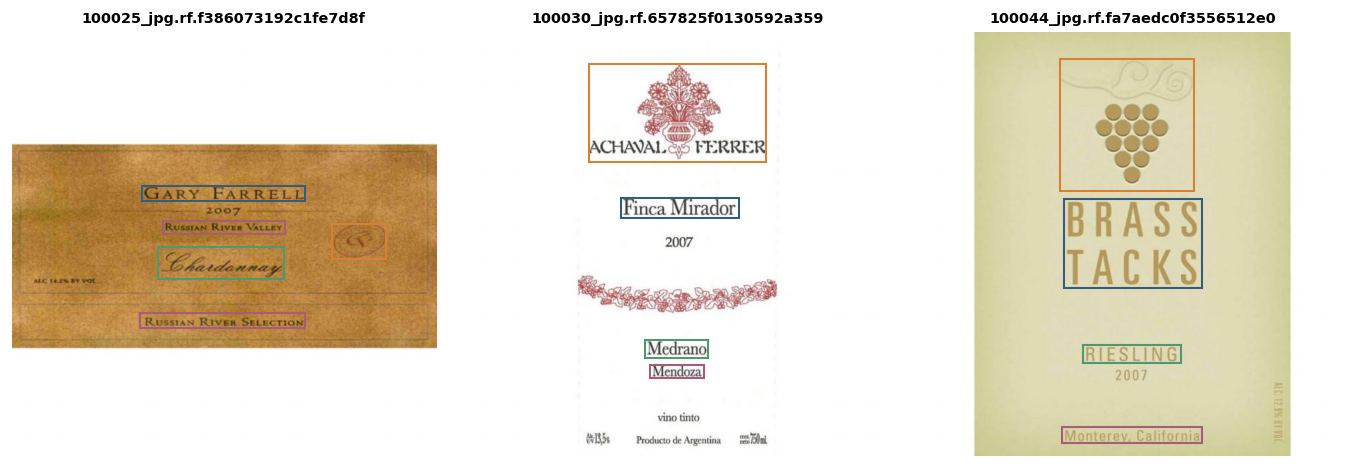

Производитель — синий, логотип — оранжевый, тип / сорт — зелёный, регион — розовый.


In [12]:
examples = presence.sum(axis=1).sort_values(ascending=False,kind='stable').index[:3]
fig, axes = plt.subplots(1,3,figsize=(12,4))
for axis, path in zip(axes, examples):
    with Image.open(path) as im:
        axis.imshow(im)
        for _, b in bbox[bbox.path.eq(path)&bbox.name.isin(TARGET.values())].iterrows():
            k=list(TARGET.values()).index(b['name'])
            x,y=(b.xc-b.w/2)*im.width,(b.yc-b.h/2)*im.height
            axis.add_patch(Rectangle((x,y),b.w*im.width,b.h*im.height,
                           fill=False,linewidth=1.3,edgecolor=COLORS[k]))
    axis.set_title(Path(path).name[:32],fontsize=9);axis.axis('off')
plt.tight_layout();plt.show()
print('Производитель — синий, логотип — оранжевый, тип / сорт — зелёный, регион — розовый.')